# House Prices — EDA

Exploratory analysis for the [House Prices: Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques) competition.

**Target:** `SalePrice` (regression). Leaderboard metric is RMSE on `log1p(SalePrice)`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme()

df = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
target = "SalePrice"


## 1. First look

Basic look at the raw rows.


In [2]:
df.head(10)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,1Fam,1.5Fin,5,5,1993,1995,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,Wood,Gd,TA,No,GLQ,732,Unf,0,64,796,GasA,Ex,Y,SBrkr,796,566,0,1362,1,0,1,1,1,1,TA,5,Typ,0,NaN,Attchd,1993.0,Unf,2,480,TA,TA,Y,40,30,0,320,0,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,1Fam,1Story,8,5,2004,2005,Gable,CompShg,VinylSd,VinylSd,Stone,186.0,Gd,TA,PConc,Ex,TA,Av,GLQ,1369,Unf,0,317,1686,GasA,Ex,Y,SBrkr,1694,0,0,1694,1,0,2,0,3,1,Gd,7,Typ,1,Gd,Attchd,2004.0,RFn,2,636,TA,TA,Y,255,57,0,0,0,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NWAmes,PosN,Norm,1Fam,2Story,7,6,1973,1973,Gable,CompShg,HdBoard,HdBoard,Stone,240.0,TA,TA,CBlock,Gd,TA,Mn,ALQ,859,BLQ,32,216,1107,GasA,Ex,Y,SBrkr,1107,983,0,2090,1,0,2,1,3,1,TA,7,Typ,2,TA,Attchd,1973.0,RFn,2,484,TA,TA,Y,235,204,228,0,0,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,OldTown,Artery,Norm,1Fam,1.5Fin,7,5,1931,1950,Gable,CompShg,BrkFace,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,TA,No,Unf,0,Unf,0,952,952,GasA,Gd,Y,FuseF,1022,752,0,1774,0,0,2,0,2,2,TA,8,Min1,2,TA,Detchd,1931.0,Unf,2,468,Fa,TA,Y,90,0,205,0,0,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,BrkSide,Artery,Artery,2fmCon,1.5Unf,5,6,1939,1950,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,BrkTil,TA,TA,No,GLQ,851,Unf,0,140,991,GasA,Ex,

## 2. Basic info

Number of samples, number of features, data types, memory.


In [3]:
print(df.shape)
df.info()


(1460, 81)
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [4]:
df.describe()


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1900.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,223.000000,795.750000,882.000000,0.000000,0.000000,1129.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1961.000000,1.000000,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,477.500000,991.500000,1087.000000,0.000000,0.000000,1464.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1980.000000,2.000000,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,808.000000,1298.250000,1391.250000,728.000000,0.000000,1776.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,2336.000000,6110.000000,4692.000000,2065.000000,572.000000,5642.000000,3.000000,2.000000,3.000000,2.000000,8.000000,3.000000,14.000000,3.000000,2010.000000,4.000000,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


| Role | Columns |
|---|---|
| ID | Id |
| Target | SalePrice |
| Numeric | MSSubClass, LotFrontage, LotArea, OverallQual, OverallCond, YearBuilt, YearRemodAdd, MasVnrArea, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, 1stFlrSF, 2ndFlrSF, LowQualFinSF, GrLivArea, BsmtFullBath, BsmtHalfBath, FullBath, HalfBath, BedroomAbvGr, KitchenAbvGr, TotRmsAbvGrd, Fireplaces, GarageYrBlt, GarageCars, GarageArea, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, MiscVal, MoSold, YrSold |
| Categorical | MSZoning, Street, Alley, LotShape, LandContour, Utilities, LotConfig, LandSlope, Neighborhood, Condition1, Condition2, BldgType, HouseStyle, RoofStyle, RoofMatl, Exterior1st, Exterior2nd, MasVnrType, ExterQual, ExterCond, Foundation, BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2, Heating, HeatingQC, CentralAir, Electrical, KitchenQual, Functional, FireplaceQu, GarageType, GarageFinish, GarageQual, GarageCond, PavedDrive, PoolQC, Fence, MiscFeature, SaleType, SaleCondition |
| Text / structured | — (none) |

Split is by pandas dtype (36 numeric, 43 object). Watch the columns whose *dtype* disagrees with their *meaning* — handle these before encoding:

- **MSSubClass** — numeric dtype but a dwelling-type code; treat as nominal categorical.
- **MoSold, YrSold** — stored as ints but really calendar time / cyclical, not quantities.
- **OverallQual, OverallCond** — numeric and genuinely ordinal (1–10), fine as-is.
- Many object columns are ordinal quality grades (Ex > Gd > TA > Fa > Po): ExterQual, ExterCond, BsmtQual, BsmtCond, HeatingQC, KitchenQual, FireplaceQu, GarageQual, GarageCond, PoolQC — encode with an order, not one-hot.

## 3. Duplicates

Investigate the nature of any duplicates before dropping. (`Id` is a unique key, so drop it from the check.)


In [5]:
df.drop(columns="Id").duplicated().sum()
# -> investigate, then df = df.drop_duplicates() if justified


np.int64(0)

## 4. Unique values

Look for categorical features and constant (single-value) columns to drop.


In [6]:
nunique = df.nunique().sort_values()
nunique.head(20)


CentralAir      2
Utilities       2
Street          2
Alley           2
BsmtHalfBath    3
LandSlope       3
GarageFinish    3
HalfBath        3
MasVnrType      3
PavedDrive      3
PoolQC          3
FullBath        4
BsmtExposure    4
ExterQual       4
MiscFeature     4
BsmtFullBath    4
Fence           4
KitchenQual     4
BsmtCond        4
Fireplaces      4
dtype: int64

In [7]:
# constant columns (candidates to drop)
constant_cols = nunique[nunique <= 1].index.tolist()
constant_cols


[]

- No constant columns (nothing to drop).
- Low cardinality → categorical: most object columns have 2–9 levels (quality/condition grades, zoning, types).
- Highest cardinality is Neighborhood (25), then Exterior2nd (16) / Exterior1st (15) — still closed sets, so encode them; no high-cardinality free text to mine.

## 5. Correlation & leakage

Check correlation among features and with the target. Look for data leaks.


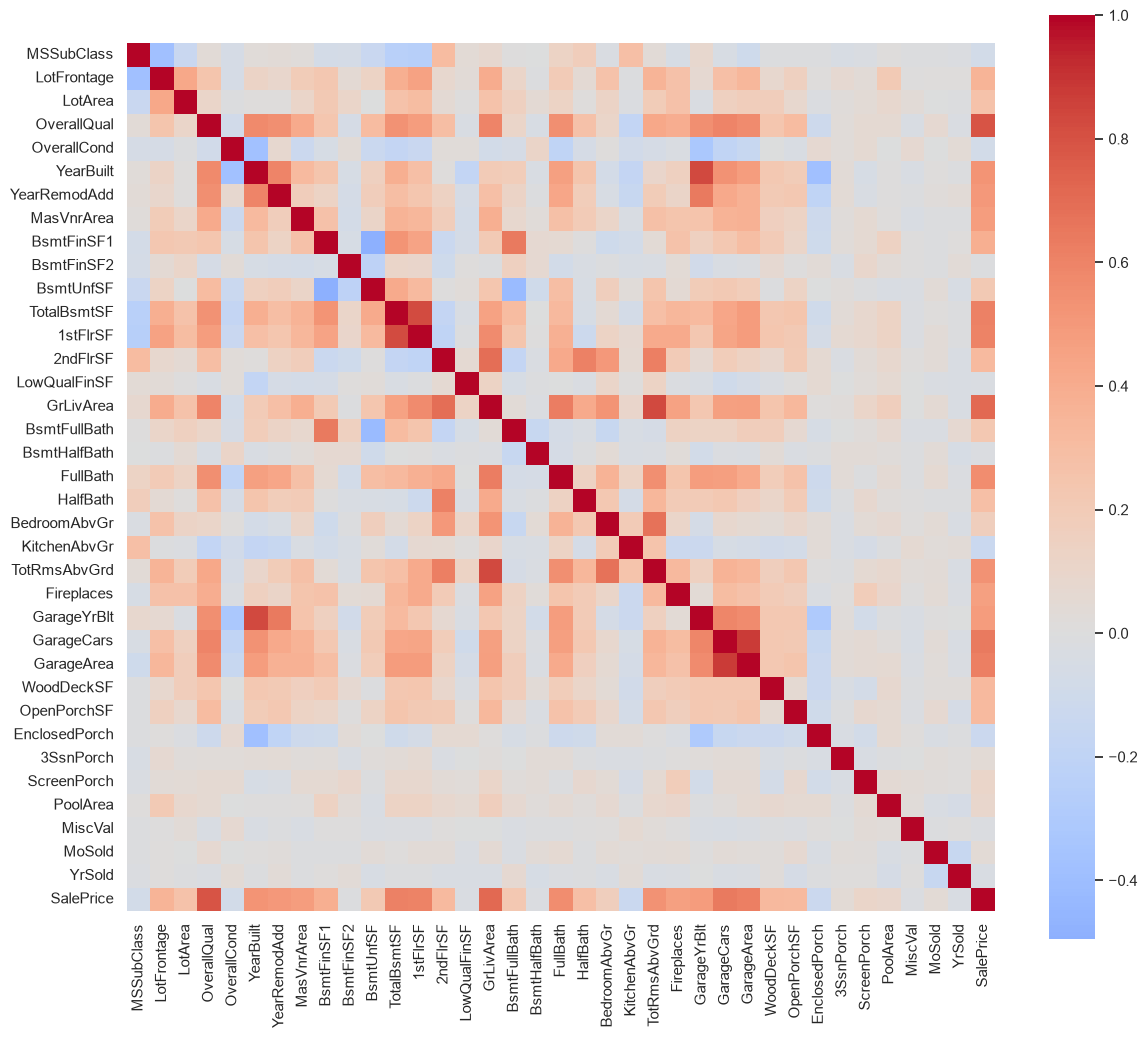

In [8]:
num_df = df.select_dtypes("number").drop(columns="Id")
corr = num_df.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr, annot=False, cmap="coolwarm", center=0, square=True,
            xticklabels=True, yticklabels=True)
plt.show()

In [9]:
# highly correlated feature pairs (candidate redundancies / leakage)
threshold = 0.9
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
pairs[pairs.abs() > threshold]


Series([], dtype: float64)

- No pair near ±1 → no 100%-correlated columns to drop (highest is GarageCars–GarageArea at 0.88).
- Strongest vs target: OverallQual (0.79), GrLivArea (0.71), GarageCars (0.64), GarageArea (0.62).
- Redundant-but-not-identical pairs to watch: GarageCars–GarageArea (0.88), YearBuilt–GarageYrBlt (0.83), GrLivArea–TotRmsAbvGrd (0.83), TotalBsmtSF–1stFlrSF (0.82).

**Leakage checks:** (1) train/test row overlap, (2) single-feature models — R² near 1.0 would mean a feature encodes the target, (3) Id — R² above 0 would mean row order carries signal.

In [10]:
print("Id overlap:", len(set(df["Id"]) & set(test["Id"])))
print("train Id range:", df["Id"].min(), "-", df["Id"].max())
print("test  Id range:", test["Id"].min(), "-", test["Id"].max())

Id overlap: 0
train Id range: 1 - 1460
test  Id range: 1461 - 2919


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

y = np.log1p(df[target])

def single_feature_r2(col):
    """CV R2 of a small forest trained on one column alone."""
    pipe = Pipeline([
        ("pre", ColumnTransformer([("f", SimpleImputer(strategy="median"), [col])])),
        ("rf", RandomForestRegressor(n_estimators=100, random_state=42)),
    ])
    return cross_val_score(pipe, df[[col]], y, cv=5, scoring="r2").mean()

for col in ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "YearBuilt", "Id"]:
    print(f"{col:12s} single-feature R2 = {single_feature_r2(col):.3f}")

OverallQual  single-feature R2 = 0.669
GrLivArea    single-feature R2 = 0.373
GarageCars   single-feature R2 = 0.482
TotalBsmtSF  single-feature R2 = 0.296
YearBuilt    single-feature R2 = 0.391
Id           single-feature R2 = -0.435


- No row overlap; train Ids are 1–1460, test 1461–2919 (disjoint) → Id is just a row counter, not a shared key.
- Best single feature is OverallQual (R² 0.67) — strong but sane; nothing near the 0.95+ leakage zone, so no feature is a price proxy.
- Id R² < 0 (worse than predicting the mean) → row order carries no signal.
- Every column is a property attribute or sale descriptor known at sale time; none is derived from SalePrice → no target leakage.

## 6. NaNs

Number of NaNs per column, and how missingness relates to the target.

> Many "NaN" values here are meaningful (e.g. `PoolQC = NA` means *no pool*) — check `data/data_description.txt` before imputing.


In [12]:
na = df.isna().sum()
na = na[na > 0].sort_values(ascending=False)
pd.DataFrame({"n_missing": na, "pct": (na / len(df) * 100).round(1)})


,n_missing,pct
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


In [13]:
# does missingness in a column relate to the target?
# col = "LotFrontage"
# df.groupby(df[col].isna())[target].median()


Most NaNs here encode **"feature absent"**, not missing data — so they're filled before any statistical imputation (→ `src/features.py`):

- **NA → `"None"`** (15 categorical): Alley, MasVnrType, BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2, FireplaceQu, GarageType, GarageFinish, GarageQual, GarageCond, PoolQC, Fence, MiscFeature.
- **NA → `0`** (10 numeric, "none of this feature"): MasVnrArea, GarageYrBlt, GarageCars, GarageArea, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, BsmtFullBath, BsmtHalfBath.
- **Genuinely missing** (needs imputation): **LotFrontage** (259) → per-neighborhood median, learned on the training folds only so CV never leaks; **Electrical** (1) → mode.

## 7. Target analysis

`SalePrice` distribution and task setting (regression). The metric uses `log1p`, so check the log-transformed target too.


In [14]:
df[target].describe()


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

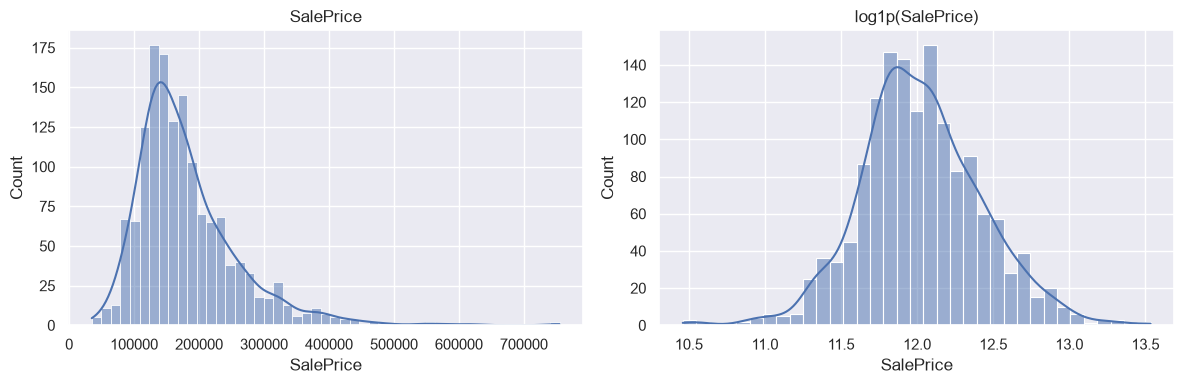

skew: 1.883 | log skew: 0.121


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[target], kde=True, ax=axes[0])
axes[0].set_title("SalePrice")
sns.histplot(np.log1p(df[target]), kde=True, ax=axes[1])
axes[1].set_title("log1p(SalePrice)")
plt.tight_layout()
plt.show()

print("skew:", df[target].skew().round(3), "| log skew:", np.log1p(df[target]).skew().round(3))


## 8. Feature distributions

Look for skewness, outliers, multimodal distributions, and train/test distribution shift.

> Outliers != anomalies. Don't drop instantly — try rounding or median first, and run a domain sanity check.


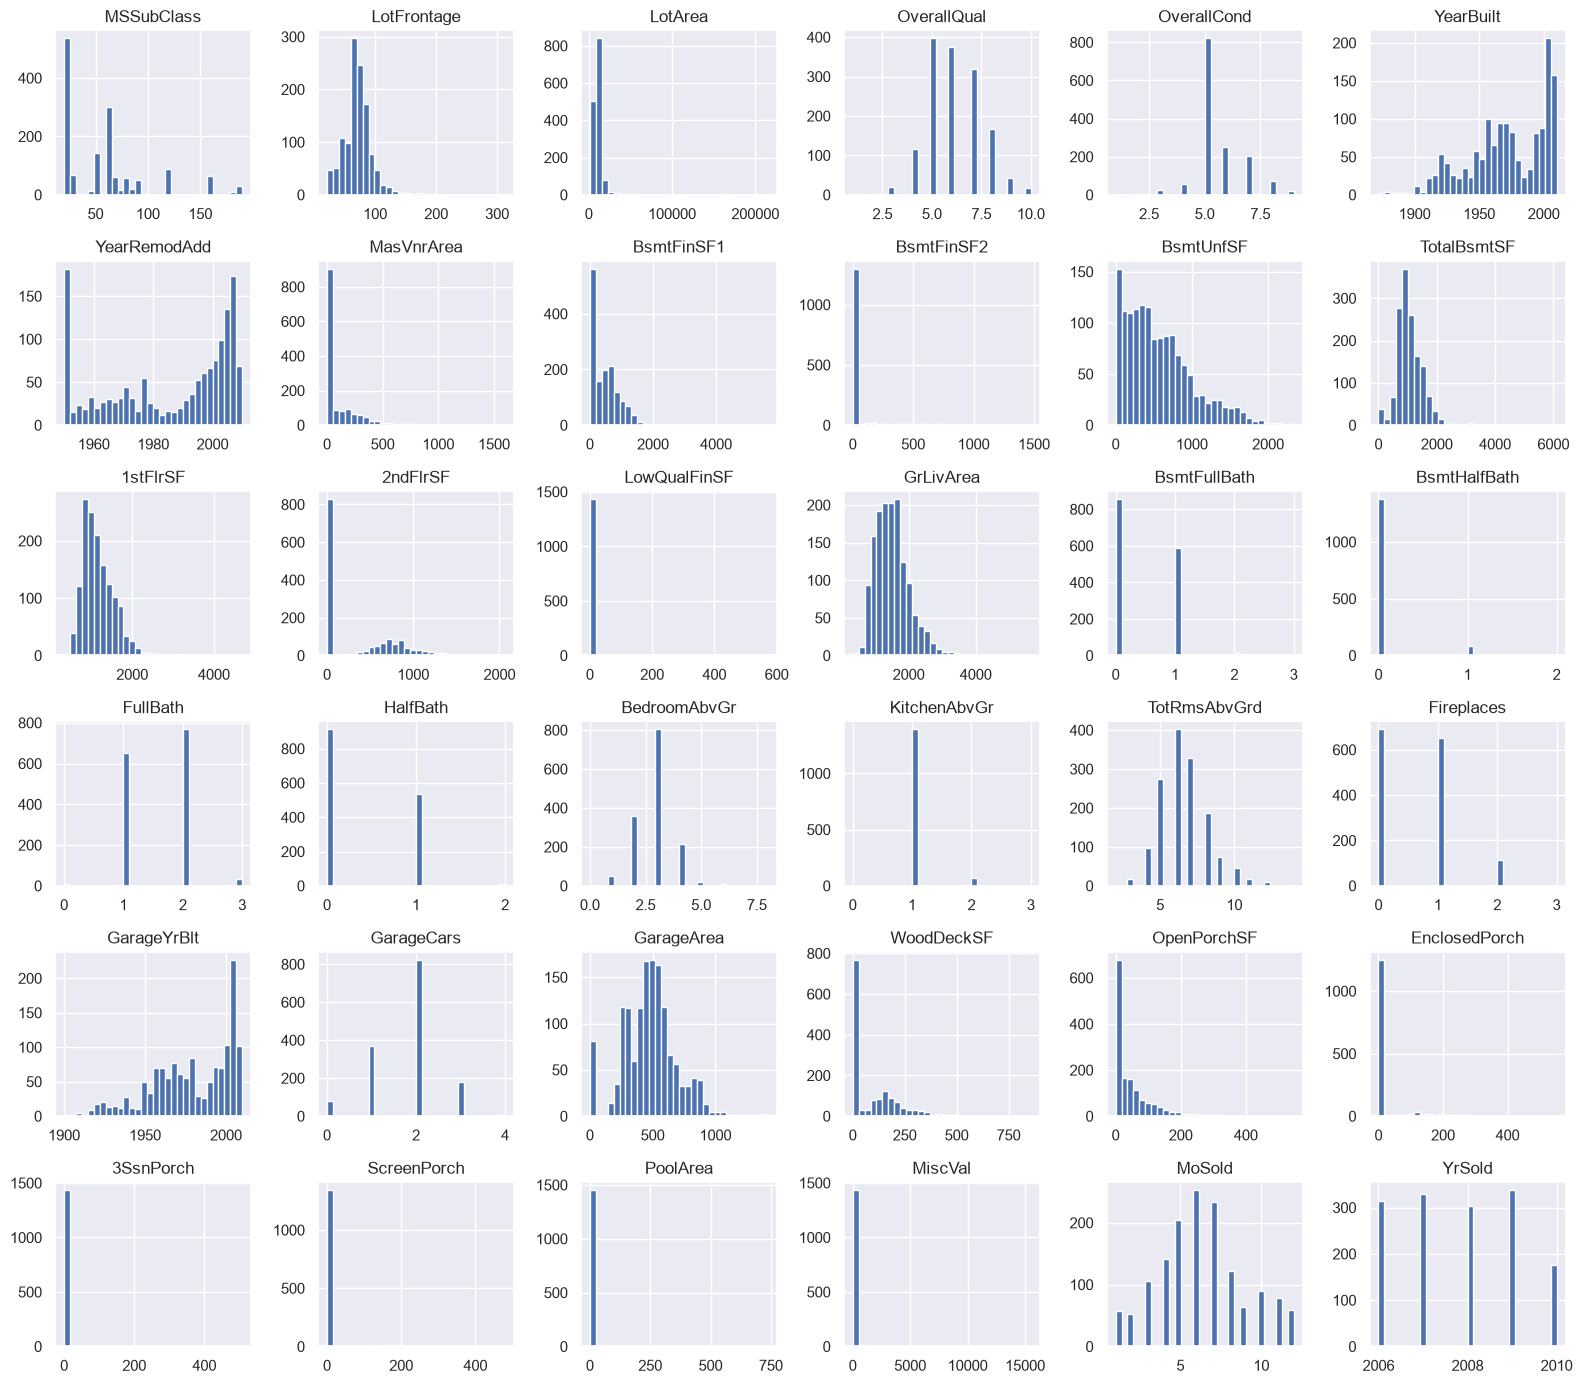

In [16]:
num_cols = num_df.columns.drop(target)
df[num_cols].hist(figsize=(16, 14), bins=30)
plt.tight_layout()
plt.show()


In [17]:
# skewness ranking of numeric features
df[num_cols].skew().sort_values(ascending=False).head(15)


MiscVal          24.476794
PoolArea         14.828374
LotArea          12.207688
3SsnPorch        10.304342
LowQualFinSF      9.011341
KitchenAbvGr      4.488397
BsmtFinSF2        4.255261
ScreenPorch       4.122214
BsmtHalfBath      4.103403
EnclosedPorch     3.089872
MasVnrArea        2.669084
OpenPorchSF       2.364342
LotFrontage       2.163569
BsmtFinSF1        1.685503
WoodDeckSF        1.541376
dtype: float64

In [18]:
# single categorical feature
# col = "Neighborhood"
# df[col].value_counts().plot(kind="bar", figsize=(10, 4)); plt.show()


In [19]:
# distribution shift: compare a feature in train vs test
# col = "GrLivArea"
# sns.kdeplot(df[col], label="train"); sns.kdeplot(test[col], label="test"); plt.legend(); plt.show()


### 8a. Process outliers / domain sanity check

Inspect suspicious points against domain knowledge before deciding to cap, round, or drop.


In [20]:
# known example: a few huge GrLivArea houses sold cheap
# sns.scatterplot(data=df, x="GrLivArea", y=target); plt.show()


## 9. Categorical features

Find and encode categorical features. Distinguish *ordinal* (quality grades like `Ex > Gd > TA > ...`) from *nominal* columns.


In [21]:
cat_cols = df.select_dtypes("object").columns.tolist()
print(len(cat_cols), "categorical columns")
cat_cols


43 categorical columns


/var/folders/9p/97s3q6n5449fjz3r66hzv9bh0000gn/T/ipykernel_10144/1232556038.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes("object").columns.tolist()


['MSZoning',
 'Street',
 'Alley',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'Heating',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 'KitchenQual',
 'Functional',
 'FireplaceQu',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'PoolQC',
 'Fence',
 'MiscFeature',
 'SaleType',
 'SaleCondition']

In [22]:
# cardinality per categorical column
df[cat_cols].nunique().sort_values(ascending=False)
# encoding strategy lives in src/features.py


Neighborhood     25
Exterior2nd      16
Exterior1st      15
SaleType          9
Condition1        9
Condition2        8
HouseStyle        8
RoofMatl          8
Functional        7
BsmtFinType2      6
Heating           6
RoofStyle         6
SaleCondition     6
BsmtFinType1      6
GarageType        6
Foundation        6
Electrical        5
FireplaceQu       5
HeatingQC         5
GarageQual        5
GarageCond        5
MSZoning          5
LotConfig         5
ExterCond         5
BldgType          5
BsmtExposure      4
MiscFeature       4
Fence             4
LotShape          4
LandContour       4
BsmtCond          4
KitchenQual       4
ExterQual         4
BsmtQual          4
LandSlope         3
GarageFinish      3
MasVnrType        3
PavedDrive        3
PoolQC            3
Utilities         2
CentralAir        2
Street            2
Alley             2
dtype: int64

- **Ordinal → 0–5** (None/Po/Fa/TA/Gd/Ex): ExterQual, ExterCond, BsmtQual, BsmtCond, HeatingQC, KitchenQual, FireplaceQu, GarageQual, GarageCond, PoolQC.
- **Nominal → one-hot**: everything else. `MSSubClass` is numeric-coded but nominal → cast to string first.

## 10. Optimization

Optimize the dataset — downcast dtypes, drop redundant columns, reduce memory.


In [23]:
df.memory_usage(deep=True).sum() / 1e6  # MB
# e.g. pd.to_numeric(..., downcast=...), category dtype for low-cardinality strings


np.float64(3.600842)

## 11. Prepare preprocessing pipeline

Consolidate findings into the pipeline (`src/features.py`, `src/pipeline.py`): imputation, encoding, target transform, feature engineering.

**Engineered features:**
- `TotalSF` = TotalBsmtSF + 1stFlrSF + 2ndFlrSF (collapses the correlated SF cols from §5)
- `TotalBath` = FullBath + 0.5·HalfBath + BsmtFullBath + 0.5·BsmtHalfBath
- `TotalPorchSF` = sum of the 5 porch/deck cols
- `HouseAge` = YrSold − YearBuilt; `RemodAge` = YrSold − YearRemodAdd
- `Has*` flags: HasPool, Has2ndFloor, HasGarage, HasBsmt, HasFireplace

_(No image/text modalities — this box collapses to the tabular pipeline.)_

In [24]:
# from src.features import ...   # wire EDA decisions back into the pipeline
